<a href="https://colab.research.google.com/github/x-rohanpatil/DAV-lab-/blob/main/Copy_of_DAV_06_Feature_engineering_Rohan_police_patil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt



from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
data = pd.DataFrame({
    "Study_Hours": [2,4,5,7,8,10],
    "Attendance_percent": [50,60,65,75,85,95],
    "Assignment_Score": [35,45,55,65,80,95],
    "FInal_Marks": [38,48,56,68,82,94],
})
display(data)

,Study_Hours,Attendance_percent,Assignment_Score,FInal_Marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [ ]:
features = data[["Study_Hours","Attendance_percent","Assignment_Score"]]
print("Minimum values:")
print(features.min())
print("Maximum values:")
print(features.max())

Minimum values:
Study_Hours            2
Attendance_percent    50
Assignment_Score      35
dtype: int64
Maximum values:
Study_Hours           10
Attendance_percent    95
Assignment_Score      95
dtype: int64


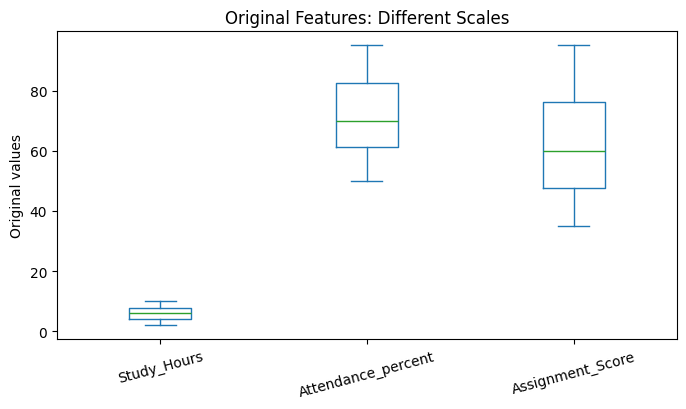

In [ ]:
features.plot(kind="box",figsize=(8,4))
plt.title("Original Features: Different Scales")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
normalizer = MinMaxScaler()
normalized_array = normalizer.fit_transform(features)
normalized_df = pd.DataFrame(normalized_array, columns=features.columns,index=features.index)
display(normalized_df.round())

,Study_Hours,Attendance_percent,Assignment_Score
0,0.0,0.0,0.0
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,1.0,1.0,0.0
4,1.0,1.0,1.0
5,1.0,1.0,1.0


In [ ]:
print("Minimum after normalization:")
print(normalized_df.min())
print("Maximum after normalization:")
print(normalized_df.max())




Minimum after normalization:
Study_Hours           0.0
Attendance_percent    0.0
Assignment_Score      0.0
dtype: float64
Maximum after normalization:
Study_Hours           1.0
Attendance_percent    1.0
Assignment_Score      1.0
dtype: float64


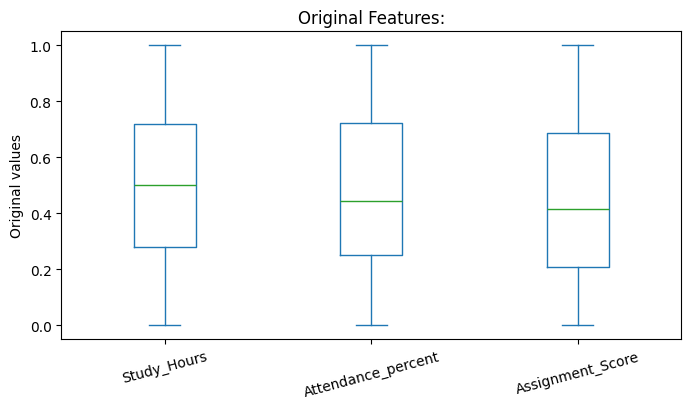

In [ ]:
normalized_df.plot(kind="box", figsize=(8,4))
plt.title("Original Features:")
plt.ylabel("Original values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
standardizer = StandardScaler()
standardized_array = standardizer.fit_transform(features)
standardized_df = pd.DataFrame(standardized_array, columns=features.columns,index=features.index)
display(standardized_df.round())

,Study_Hours,Attendance_percent,Assignment_Score
0,-2.0,-1.0,-1.0
1,-1.0,-1.0,-1.0
2,-0.0,-0.0,-0.0
3,0.0,0.0,0.0
4,1.0,1.0,1.0
5,2.0,2.0,2.0


In [ ]:
print("Means after standardization:")
print(standardized_df.mean().round(6))
print()
print("Standard deviations after standardization: ")
print(standardized_df.std(ddof=0),round(6))




Means after standardization:
Study_Hours           0.0
Attendance_percent   -0.0
Assignment_Score      0.0
dtype: float64

Standard deviations after standardization: 
Study_Hours           1.0
Attendance_percent    1.0
Assignment_Score      1.0
dtype: float64 6


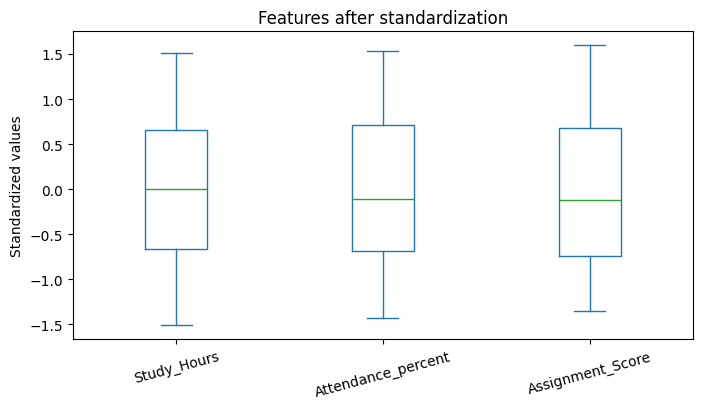

In [ ]:
standardized_df.plot(kind="box", figsize=(8,4))
plt.title("Features after standardization")
plt.ylabel("Standardized values")
plt.xticks(rotation=15)
plt.show()

In [ ]:
scaled_features= StandardScaler().fit_transform(features)
pca= PCA(n_components=2)
pca_array = pca.fit_transform(scaled_features)
pca_df = pd.DataFrame(pca_array, columns=["PC1","PC2"],index=features.index)
display(pca_df.round(3))

,PC1,PC2
0,-2.476,-0.115
1,-1.376,0.069
2,-0.684,-0.001
3,0.416,0.182
4,1.440,-0.078
5,2.682,-0.057


In [ ]:
variance_ratios = pca.explained_variance_ratio_
for component, ratio in zip(["PC1","PC2"],variance_ratios):
    print(f"Variance explained by {component}: {ratio:.2%} of the variance")
total_retained = variance_ratios.sum()
print(f"Total variance retained: {total_retained:.2%}")


Variance explained by PC1: 99.62% of the variance
Variance explained by PC2: 0.34% of the variance
Total variance retained: 99.96%


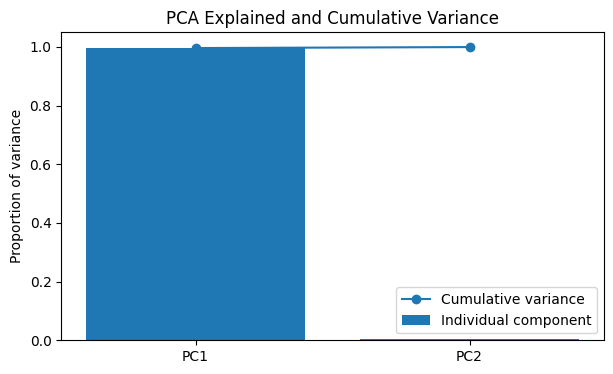

In [ ]:
component_names = ["PC1", "PC2"]
cumulative_variance = variance_ratios.cumsum()

plt.figure(figsize=(7, 4))
plt.bar(component_names, variance_ratios)
plt.plot(component_names, cumulative_variance, marker="o")
plt.ylim(0, 1.05)
plt.ylabel("Proportion of variance")
plt.title("PCA Explained and Cumulative Variance")
plt.legend(["Cumulative variance", "Individual component"])
plt.show()